In [1]:
import netCDF4
import xarray as xr
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime

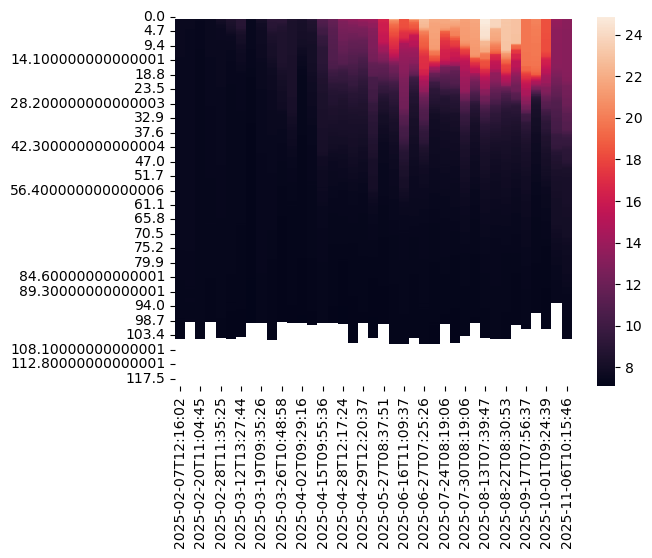

In [2]:
folder = "../data/Level2"
qa = True
files = [os.path.join(folder, f) for f in os.listdir(folder)]
files.sort()

files = files[-10:]

with xr.open_mfdataset(files, decode_times=False) as ds:
    t = np.array(ds.variables["time"][:].values, dtype="datetime64[s]")
    v = np.array(ds.variables["Temp"][:].values)
    d = np.array(ds.variables["depth"][:].values)
    df = pd.DataFrame(data=v,index=d, columns=t)
    sns.heatmap(df)
    plt.show()